#Classificando as espécies da flor Iris - abordagem supervisionada

##Etapa 01
Importar as bibliotecas de computação científica e aprendizado de máquina.

In [248]:
#Bibliotecas de aprendizado de máquina
from sklearn import datasets
from sklearn import svm
from sklearn.model_selection import train_test_split

#Bibliotecas de computação científica
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

##Etapa 02
Importar a base de dados Iris do sklearn e definir as classes.

In [249]:
iris_dataset = datasets.load_iris()
#print("Descrição da base de dados :: ", iris_dataset['DESCR'])

##Etapa 03
Conhecer a base de dados e plotar as características de comprimento das sépalas e pétalas para setosa e versicolor.

In [250]:
#Obter os dados
X = iris_dataset.data
Y = iris_dataset.target

In [251]:
print('Quantidade de amostras: ', X.shape)
print('\nPrimeiras 5 amostras:\n\n', X[0:5,:])
print('\nQuantidade de labels: ', Y.shape)
print('\nNome das classes: ', iris_dataset.target_names)
print('\nNome das características: ', iris_dataset.feature_names)

Quantidade de amostras:  (150, 4)

Primeiras 5 amostras:

 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

Quantidade de labels:  (150,)

Nome das classes:  ['setosa' 'versicolor' 'virginica']

Nome das características:  ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [252]:
#Selecionar as características petal widht e petal length para setosa e versicolor
data_plot = iris_dataset.data[0:150,[2,3]]
print(data_plot.shape)
#print(data_plot)

(150, 2)


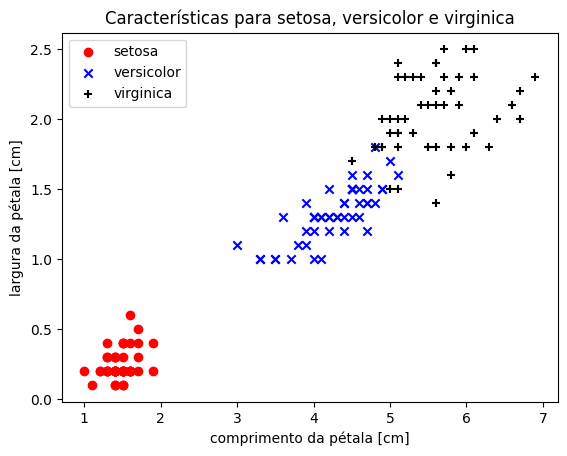

In [253]:
#Plotar os dados
plt.scatter(data_plot[:50, 0], data_plot[:50, 1],
            color='red', marker='o', label='setosa')

plt.scatter(data_plot[50:100, 0], data_plot[50:100, 1],
            color='blue', marker='x', label='versicolor')

plt.scatter(data_plot[100:150, 0], data_plot[100:150, 1],
            color='k', marker='+', label='virginica')

plt.title('Características para setosa, versicolor e virginica')
plt.xlabel('comprimento da pétala [cm]')
plt.ylabel('largura da pétala [cm]')
plt.legend(loc='upper left')

plt.show()

##Etapa 04
Partição dos dados: 75% treinamento e 25% validação.

In [254]:
#Particionar os dados

# treinamento -- 70% - 80%
# validacao -- 30% - 20%
# teste -- 5% - 10%
#Particionar os dados
x_train, x_val, y_train, y_val = train_test_split(data_plot, Y, test_size = 0.25)
x_train, x_test, y_train, y_test = train_test_split(x_train, y_train, test_size = 0.10)
print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_val', x_val.shape)
print('y_val', y_val.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)

x_train (100, 2)
y_train (100,)
x_val (38, 2)
y_val (38,)
x_test (12, 2)
y_test (12,)


In [255]:
print(y_val)

[2 1 0 2 1 1 0 1 2 2 2 2 2 0 2 1 1 2 0 0 1 0 2 2 1 1 2 2 0 0 1 0 1 2 0 1 0
 0]


In [256]:
print(y_test)

[0 2 1 1 0 0 0 2 1 1 2 1]


##Etapa 05
Realizar o treinamento do classificador.

In [257]:
svc = svm.SVC(kernel='linear').fit(x_train, y_train)

##Etapa 06
Validando os dados.

In [258]:
y_predicted = svc.predict(x_test)

In [259]:
y_predicted

array([0, 2, 1, 1, 0, 0, 0, 2, 1, 1, 2, 1])

In [260]:
y_test

array([0, 2, 1, 1, 0, 0, 0, 2, 1, 1, 2, 1])

In [261]:
true_label = 0

for i in range(len(y_test)):
  if(y_predicted[i] == y_test[i]):
    true_label = true_label + 1

test_acc = (true_label/len(y_test))*100

print('Label Real:\n', y_test)
print('Label Predito:\n ', y_predicted)
print('Acurácia da validação:', test_acc)

Label Real:
 [0 2 1 1 0 0 0 2 1 1 2 1]
Label Predito:
  [0 2 1 1 0 0 0 2 1 1 2 1]
Acurácia da validação: 100.0


##Etapa 07
Realizar a predição de uma única amostra.

In [262]:
x_test.shape

(12, 2)

In [263]:
x_val.shape

(38, 2)

In [264]:
x_test[3].shape

(2,)

In [265]:
## ERRO DE DIMENSAO NA ENTRADA DO MODELO
#y_predicted = svc.predict(x_test[3])

In [266]:
sample = np.expand_dims(x_test[3],0)
sample.shape

(1, 2)

In [267]:
predicted = svc.predict(sample)
predicted

array([1])

In [268]:
y_test[3]

np.int64(1)

In [269]:
id = 3
sample = np.expand_dims(x_val[id],0)
predicted = svc.predict(sample)

print('Resultado: ', predicted, ' - ', iris_dataset.target_names[predicted])

print('Correto', y_val[id])
if(y_val[id] == predicted):
  print('Acertou')
else:
  print('Errou')

Resultado:  [2]  -  ['virginica']
Correto 2
Acertou
